# Praktikum Pengenalan Vowel Bahasa Indonesia dengan DTW dan Model Gaussian

**Mata kuliah:** IF4071 Pemrosesan Ucapan

**Kelompok:** Kelompok 7

**Anggota:** 
- Muhammad Alfansya	(13523005)
- Shannon Aurellius Anastasya Lie (13523019)
- Dzaky Aurelia Fawwaz (13523065)
- Ferdin Arsenarendra Purtadi (13523117)
- Naomi Risaka Sitorus (13523122)

Notebook ini memuat alur lengkap akuisisi data, preprocessing, ekstraksi MFCC 39 dimensi, pembentukan template DTW, model Gaussian, pengujian tiga skenario, serta perhitungan akurasi dan confusion matrix.

## 1. Instalasi Library

Jalankan jika library belum tersedia pada environment notebook.

In [24]:
%pip install numpy pandas matplotlib seaborn soundfile scipy python_speech_features scikit-learn librosa

Note: you may need to restart the kernel to use updated packages.


## 2. Import Library & Konfigurasi

In [25]:
from pathlib import Path
from math import gcd
import re
import warnings
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import librosa

from scipy.signal import resample_poly
from python_speech_features import mfcc, delta
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
DATA_DIR = Path("data")
VOWELS = ["A", "I", "U", "E", "O"]
SAMPLE_RATE = 16000
WINLEN = 0.025
WINSTEP = 0.010
NUM_CEP = 13
N_FFT = 512
COVARIANCE_REG = 1e-3
TARGET_TEMPLATE_FRAMES = 100

np.random.seed(SEED)

print("Dataset directory:", DATA_DIR.resolve())
print("Directory exists:", DATA_DIR.exists())

Dataset directory: C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\data
Directory exists: True


## 3. Import Dataset

Penamaan file dilakukan sesuai konvensi: S{speaker}_{vowel}_{usage}_{condition}.wav

Usage: CR (closed recording), CS (closed speaker), atau OS (open speaker)

Condition: N (normal), HP (high pitch), LP (low pitch), SD (short duration), atau LD (long duration)

In [26]:
from src.data_loader import load_dataset

df = load_dataset(DATA_DIR)

df.describe()

# display the first 10 rows
display(df.head(10))
print("Total audio loaded:", len(df))

# check the distribution of usage and vowel combinations
display(df.groupby(["split", "usage", "vowel"]).size().unstack(fill_value=0))

,file_path,file_name,speaker,vowel,usage,condition,split
0,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S01_A_CR_N.wav,S01,A,CR,N,template
1,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S02_A_CR_N.wav,S02,A,CR,N,template
2,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S03_A_CR_N.wav,S03,A,CR,N,template
3,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S04_A_CR_N.wav,S04,A,CR,N,template
4,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S05_A_CR_N.wav,S05,A,CR,N,template
5,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S01_E_CR_N.wav,S01,E,CR,N,template
6,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S02_E_CR_N.wav,S02,E,CR,N,template
7,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S03_E_CR_N.wav,S03,E,CR,N,template
8,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S04_E_CR_N.wav,S04,E,CR,N,template
9,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S05_E_CR_N.wav,S05,E,CR,N,template


Total audio loaded: 230


vowel            A   E   I   O   U
split    usage                    
template CR      5   5   5   5   5
test     CR      5   5   5   5   5
         CS     25  25  25  25  25
         OS     11  11  11  11  11

## 4. Validasi File Audio

Periksa apakah lima vowel tersedia pada data template, apakah file audio bisa dibaca, serta apakah sample rate dan durasinya masuk akal.

In [27]:
summary_vowels = (
    df.groupby(["split", "usage", "vowel"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=VOWELS, fill_value=0)
)
display(summary_vowels)

summary_speakers = (
    df.groupby(["split", "usage", "speaker"])
    .size()
    .rename("file_count")
    .reset_index()
)
display(summary_speakers)

audio_info_rows = []
for row in df.itertuples(index=False):
    try:
        info = sf.info(row.file_path)
        audio_info_rows.append({
            "file_path": row.file_path,
            "sample_rate": info.samplerate,
            "channels": info.channels,
            "duration_seconds": round(info.duration, 3),
            "readable": True,
        })
    except Exception as exc:
        audio_info_rows.append({
            "file_path": row.file_path,
            "sample_rate": None,
            "channels": None,
            "duration_seconds": None,
            "readable": False,
            "error": str(exc),
        })

audio_info = pd.DataFrame(audio_info_rows)
display(audio_info.head(10))
print("All files readable:", bool(audio_info["readable"].all()))

vowel            A   I   U   E   O
split    usage                    
template CR      5   5   5   5   5
test     CR      5   5   5   5   5
         CS     25  25  25  25  25
         OS     11  11  11  11  11

,split,usage,speaker,file_count
0,template,CR,S01,5
1,template,CR,S02,5
2,template,CR,S03,5
3,template,CR,S04,5
4,template,CR,S05,5
5,test,CR,S01,5
6,test,CR,S02,5
7,test,CR,S03,5
8,test,CR,S04,5
9,test,CR,S05,5


,file_path,sample_rate,channels,duration_seconds,readable
0,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,16000,1,2.664,True
1,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,16000,1,2.576,True
2,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,16000,1,2.944,True
3,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,16000,1,2.153,True
4,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,16000,1,1.806,True
5,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,16000,1,2.014,True
6,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,16000,1,2.534,True
7,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,16000,1,2.034,True
8,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,16000,1,1.709,True
9,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,16000,1,2.207,True


All files readable: True


## 5. Preprocessing Audio & Ekstraksi MFCC 39 Dimensi

In [28]:
from src.features import extract_mfcc_39
from src.preprocessing import load_audio

feature_cache = {}
feature_errors = []

for row in df.itertuples(index=False):
    try:
        signal, sample_rate = load_audio(row.file_path, SAMPLE_RATE)
        feature_cache[row.file_path] = extract_mfcc_39(signal, sample_rate, WINLEN, WINSTEP, NUM_CEP, N_FFT)
    except Exception as exc:
        feature_errors.append({"file_path": row.file_path, "error": str(exc)})

if feature_errors:
    display(pd.DataFrame(feature_errors))
    raise RuntimeError("Failed to process some audio files.")

df["n_frames"] = df["file_path"].map(lambda path: feature_cache[path].shape[0])
df["feature_dim"] = df["file_path"].map(lambda path: feature_cache[path].shape[1])

display(df[["file_path", "speaker", "vowel", "usage", "n_frames", "feature_dim"]].head(10))
print("All features are 39-dimensional:", bool((df["feature_dim"] == 39).all()))

,file_path,speaker,vowel,usage,n_frames,feature_dim
0,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S01,A,CR,34,39
1,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S02,A,CR,105,39
2,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S03,A,CR,41,39
3,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S04,A,CR,41,39
4,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S05,A,CR,41,39
5,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S01,E,CR,31,39
6,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S02,E,CR,73,39
7,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S03,E,CR,41,39
8,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S04,E,CR,44,39
9,C:\Semester_7\Korpus_Vowel_Bahasa_Indonesia\da...,S05,E,CR,57,39


All features are 39-dimensional: True


## 6. Visualisasi Signal Raw, Hasil Preprocessing, and Hasil Ekstraksi Fitur

Plot waveform dan jumlah frame fitur untuk memeriksa bahwa proses loading serta ekstraksi berjalan.

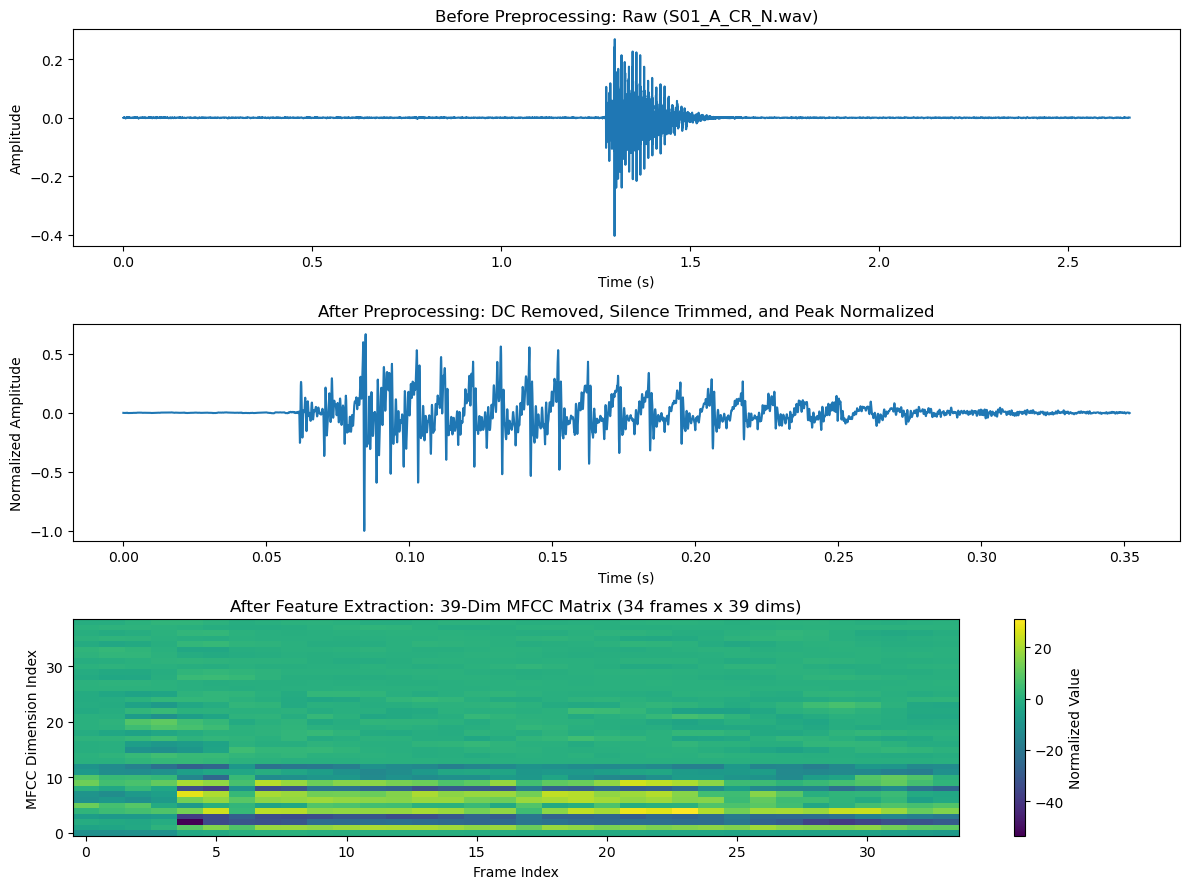

In [29]:
# take a sample audio from the dataset
sample_row = df.iloc[0]
sample_path = sample_row["file_path"]

# raw signal (before preprocessing)
raw_signal, raw_sr = sf.read(sample_path, dtype="float32")
if raw_signal.ndim == 2:
    raw_signal = raw_signal.mean(axis=1)
raw_time = np.arange(len(raw_signal)) / raw_sr

# preprocessed signal
processed_signal, processed_sr = load_audio(sample_path, SAMPLE_RATE)
processed_time = np.arange(len(processed_signal)) / processed_sr

# extracted 39-dim mfcc features
mfcc_features = feature_cache[sample_path]

# plot comparisons
fig, axes = plt.subplots(3, 1, figsize=(12, 9))

# subplot 1: raw
axes[0].plot(raw_time, raw_signal)
axes[0].set_title(f"Before Preprocessing: Raw ({sample_row['file_name']})")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")

# subplot 2: preprocessed
axes[1].plot(processed_time, processed_signal)
axes[1].set_title("After Preprocessing: DC Removed, Silence Trimmed, and Peak Normalized")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Normalized Amplitude")

# subplot 3: extracted 39-dim mfcc features
img = axes[2].imshow(mfcc_features.T, aspect="auto", origin="lower", cmap="viridis", interpolation="nearest")
axes[2].set_title(f"After Feature Extraction: 39-Dim MFCC Matrix ({mfcc_features.shape[0]} frames x 39 dims)"
)
axes[2].set_xlabel("Frame Index")
axes[2].set_ylabel("MFCC Dimension Index")
fig.colorbar(img, ax=axes[2], orientation="vertical", label="Normalized Value")

plt.tight_layout()
plt.show()

## 7. Averaged Template untuk DTW

Urutan fitur dari setiap speaker dapat memiliki jumlah frame berbeda sehingga perlu dibuat averaged template. Template setiap vowel dibangun hanya dari file pada folder `template`.


,jumlah rekaman,frame min,frame median,frame max,frame template
A,5,34,41,105,100
I,5,31,41,57,100
U,5,28,37,41,100
E,5,31,44,73,100
O,5,31,41,149,100


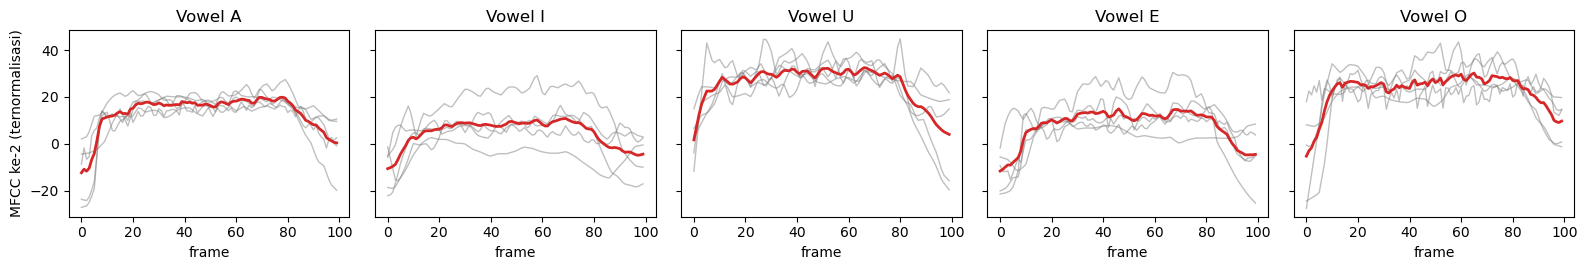

In [30]:
from src.template import TARGET_TEMPLATE_FRAMES as TEMPLATE_FRAMES, build_templates, resample_frames

# data/test/closed/recording berisi file yang identik dengan template, jadi ambil dari folder template saja
template_df = df[(df["usage"] == "CR") & (df["split"] == "test")].copy()
template_feats = {
    v: [feature_cache[path] for path in template_df[template_df["vowel"] == v]["file_path"]] for v in VOWELS
}

templates = build_templates(template_feats)

summary = pd.DataFrame({
    v: {
        "jumlah rekaman": len(fs),
        "frame min": min(len(f) for f in fs),
        "frame median": int(np.median([len(f) for f in fs])),
        "frame max": max(len(f) for f in fs),
        "frame template": len(templates[v]),
    }
    for v, fs in template_feats.items()
}).T
display(summary)

fig, axes = plt.subplots(1, len(VOWELS), figsize=(3.2 * len(VOWELS), 2.8), sharey=True)
for ax, v in zip(axes, VOWELS):
    for f in template_feats[v]:
        ax.plot(resample_frames(f, TEMPLATE_FRAMES)[:, 1], color="gray", alpha=0.5, lw=1)
    ax.plot(templates[v][:, 1], color="C3", lw=2)
    ax.set_title(f"Vowel {v}")
    ax.set_xlabel("frame")
axes[0].set_ylabel("MFCC ke-2 (ternormalisasi)")
plt.tight_layout()
plt.show()

## 8. Implementasi DTW

DTW menghitung akumulasi jarak frame dengan dynamic programming. Biaya akhir dinormalisasi terhadap panjang path agar perbandingan urutan tidak terlalu dipengaruhi jumlah langkah alignment. Input diprediksi sebagai vowel dengan biaya terkecil.


Rekaman A pertama ke template A: cost 30.796, panjang path 100 sel


template,A,I,U,E,O,prediksi
rekaman,,,,,,
A,30.796,76.175,64.500,69.571,55.281,A
I,67.036,41.447,67.344,51.657,71.088,I
U,54.094,68.309,31.857,60.707,37.003,U
E,61.250,40.110,60.480,30.145,64.254,E
O,52.793,73.484,36.767,68.700,27.470,O


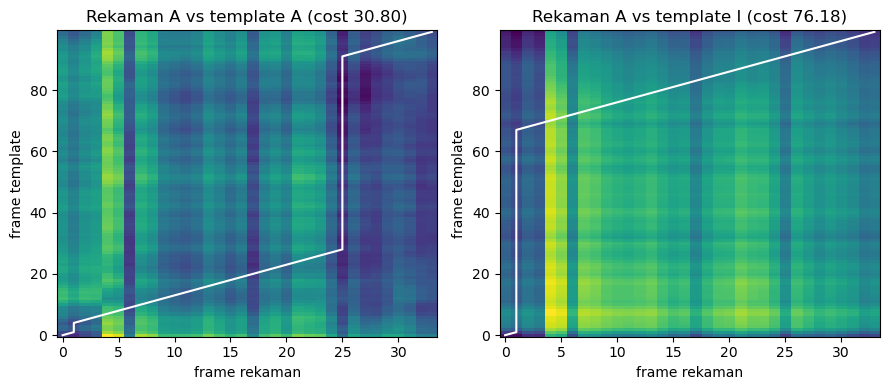

In [31]:
from src.dtw import dtw_distance, dtw_path, local_cost

X = template_feats["A"][0]
assert dtw_distance(X, X) == 0.0, "jarak DTW ke dirinya sendiri harus 0"
assert np.isclose(dtw_distance(X, templates["A"]), dtw_distance(templates["A"], X)), "DTW harus simetris"
cost, path = dtw_path(X, templates["A"])
assert np.isclose(cost, dtw_distance(X, templates["A"])), "dtw_path dan dtw_distance harus sama"
print(f"Rekaman A pertama ke template A: cost {cost:.3f}, panjang path {len(path)} sel")

cost_table = pd.DataFrame(
    {tv: {v: dtw_distance(template_feats[v][0], templates[tv]) for v in VOWELS} for tv in VOWELS}
)
cost_table["prediksi"] = cost_table[VOWELS].idxmin(axis=1)
cost_table.index.name = "rekaman"
cost_table.columns.name = "template"
display(cost_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, v in zip(axes, ["A", "I"]):
    c, p = dtw_path(X, templates[v])
    ax.imshow(local_cost(X, templates[v]).T, origin="lower", aspect="auto", cmap="viridis")
    ax.plot(p[:, 0], p[:, 1], color="white", lw=1.5)
    ax.set_title(f"Rekaman A vs template {v} (cost {c:.2f})")
    ax.set_xlabel("frame rekaman")
    ax.set_ylabel("frame template")
plt.tight_layout()
plt.show()

## 9. Implementasi Model Gaussian

Baseline Gaussian di sini menggabungkan frame MFCC dari seluruh rekaman template pada kelas vowel yang sama. Setiap kelas memiliki mean dan covariance 39 × 39. Karena setiap vowel hanya memiliki 184-312 frame latih untuk 819 parameter, korelasi antar dimensi pada covariance disusutkan ke diagonalnya (`shrinkage=0.6`, varians tiap dimensi tidak berubah) dan diberi regularisasi diagonal `1e-3` agar stabil secara numerik. Saat pengujian, negative log-likelihood dihitung untuk setiap frame dan dirata-ratakan sepanjang rekaman. Model dengan nilai terkecil menjadi prediksi.


,jumlah frame latih,condition number cov,eigen min cov
A,262.0,12839.287,0.037
I,210.0,19659.988,0.022
U,184.0,11373.760,0.026
E,246.0,12217.845,0.031
O,312.0,13335.903,0.025


model,A,I,U,E,O,prediksi
rekaman,,,,,,
A,88.64,120.21,118.00,112.03,104.87,A
I,132.00,91.34,121.23,106.40,136.06,I
U,122.36,120.64,93.18,123.32,109.54,U
E,120.92,93.70,113.53,88.09,120.67,E
O,104.21,110.57,94.58,114.34,87.84,O


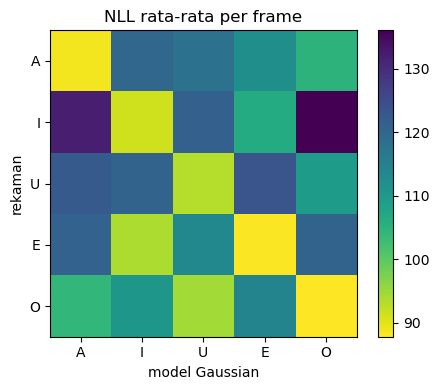

In [32]:
from src.gaussian import fit_gaussian, nll

gaussians = {v: fit_gaussian(template_feats[v]) for v in VOWELS}

summary = pd.DataFrame({
    v: {
        "jumlah frame latih": sum(len(f) for f in template_feats[v]),
        "condition number cov": np.linalg.cond(gaussians[v][1]),
        "eigen min cov": np.linalg.eigvalsh(gaussians[v][1]).min(),
    }
    for v in VOWELS
}).T
display(summary.round(3))

# NLL rekaman template pertama tiap vowel terhadap model setiap vowel (makin kecil makin cocok)
nll_table = pd.DataFrame(
    {tv: {v: nll(template_feats[v][0], gaussians[tv]) for v in VOWELS} for tv in VOWELS}
)
nll_table["prediksi"] = nll_table[VOWELS].idxmin(axis=1)
assert (nll_table["prediksi"] == nll_table.index).all(), "rekaman latih seharusnya paling cocok dengan modelnya sendiri"
nll_table.index.name = "rekaman"
nll_table.columns.name = "model"
display(nll_table.round(2))

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(nll_table[VOWELS].values.astype(float), cmap="viridis_r")
ax.set_xticks(range(len(VOWELS)), VOWELS)
ax.set_yticks(range(len(VOWELS)), VOWELS)
ax.set_xlabel("model Gaussian")
ax.set_ylabel("rekaman")
ax.set_title("NLL rata-rata per frame")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 10. Persiapan Skenario Pengujian

Template DTW dan model Gaussian hanya dibangun dari folder `data/template`, lalu diuji pada skenario berikut:

- **Closed recordings** (`data/test/closed/recording`): file template yang sama diuji kembali. Hasilnya hanya diagnostik karena model telah dibangun menggunakan rekaman tersebut.
- **Closed speakers** (`data/test/closed/speaker`): rekaman lain dari speaker yang juga terdapat pada data template, dalam lima kondisi (N, HP, LP, SD, LD).
- **Open speakers** (`data/test/open`): rekaman dari speaker di luar data template, yaitu anggota kelompok lain.
- *(Opsional)* **Leave-one-speaker-out** (`loso`): template dibangun dari 4 speaker, lalu diuji pada data closed speaker milik speaker ke-5, bergiliran untuk setiap speaker.

Sebelum pengujian, `check_dataset` memastikan pengujian adil dan label benar: nama file sesuai konvensi, label folder sama dengan label nama file, tidak ada file identik dengan label berbeda, closed recording identik dengan template, closed speaker tidak memuat rekaman template, speaker open bukan speaker template, dan tidak ada rekaman yang belum dipotong (durasi > 10 detik). Jika ada pelanggaran, eksekusi berhenti dengan pesan yang menyebutkan file bermasalah.

In [33]:
# Jika file di src/ diubah, restart kernel agar perubahan terbaca
from src.run_experiments import SCENARIO_DIRS, check_dataset, run_all, scan_dataset

dataset = scan_dataset(DATA_DIR)
for warning in check_dataset(dataset):
    print("[peringatan]", warning)

# Jumlah file per skenario dan vowel
pd.crosstab(dataset.scenario, dataset.vowel, margins=True, margins_name="Total").reindex(
    index=list(SCENARIO_DIRS) + ["Total"], columns=VOWELS + ["Total"], fill_value=0
)

vowel,A,I,U,E,O,Total
scenario,,,,,,
template,5,5,5,5,5,25
closed_recording,5,5,5,5,5,25
closed_speaker,25,25,25,25,25,125
open,11,11,11,11,11,55
Total,46,46,46,46,46,230


In [34]:
# Speaker dan kondisi rekaman pada setiap skenario
join_unique = lambda s: ", ".join(sorted(s.dropna().unique())) or "-"
dataset.groupby("scenario").agg(
    jumlah_file=("file", "size"),
    speaker=("speaker", join_unique),
    kondisi=("condition", join_unique),
).reindex(list(SCENARIO_DIRS)).fillna({"jumlah_file": 0, "speaker": "-", "kondisi": "-"}).astype({"jumlah_file": int})

,jumlah_file,speaker,kondisi
scenario,,,
template,25,"S01, S02, S03, S04, S05",N
closed_recording,25,"S01, S02, S03, S04, S05",N
closed_speaker,125,"S01, S02, S03, S04, S05","HP, LD, LP, N, SD"
open,55,"G03_S01, G03_S02, G03_S03, G03_S05, G04_S03, G...",N


## 11. Pengujian

`run_all` menjalankan seluruh alur pengujian: ekstraksi MFCC setiap file, membangun template DTW dan model Gaussian sekali dari data template, lalu mengenali setiap file uji pada setiap skenario. Prediksi adalah vowel dengan skor terkecil (cost DTW atau negative log-likelihood).

Hasil disimpan ke `results/predictions.csv`, dengan **satu baris per file uji x sistem**:

| Kolom | Isi |
|---|---|
| `file`, `speaker`, `condition` | identitas rekaman uji |
| `scenario` | `closed_recording`, `closed_speaker`, `open`, atau `loso` |
| `system` | `dtw`, `gaussian`, atau `dtw_nn` (DTW ke setiap template individual, tanpa dirata-rata) |
| `vowel_true`, `pred`, `correct` | label sebenarnya, hasil prediksi, dan 1 jika benar |
| `score_A` - `score_O` | skor ketidakmiripan terhadap setiap vowel (makin kecil makin mirip) |
| `margin` | selisih skor terbaik kedua dengan skor terbaik (makin besar makin yakin) |
| `n_frames`, `time_ms` | jumlah frame MFCC dan waktu recognition |

File ini menjadi sumber seluruh tabel akurasi dan confusion matrix pada bagian selanjutnya. Konfigurasi run dicatat di `results/run_info.json`.

In [35]:
SCENARIOS = ["closed_recording", "closed_speaker", "open"]  # opsional: tambahkan "loso"
SYSTEMS = ["dtw", "gaussian"]                               # opsional: tambahkan "dtw_nn"

results = run_all(DATA_DIR, "results", scenarios=SCENARIOS, systems=SYSTEMS)
results.head(10)

[selesai] closed_recording: 50 prediksi (2.4 s)
[selesai] closed_speaker: 250 prediksi (11.6 s)
[selesai] open: 110 prediksi (4.5 s)

Cek cepat akurasi (%); tabel resmi dihitung P5 dari predictions.csv:
system              dtw  gaussian
scenario                         
closed_recording  100.0     100.0
closed_speaker     84.0      88.0
open               85.5      81.8

Hasil disimpan di results\predictions.csv dan results\run_info.json


,file,speaker,vowel_true,condition,scenario,system,pred,correct,score_A,score_I,score_U,score_E,score_O,margin,n_frames,time_ms
0,S01_A_CR_N.wav,S01,A,N,closed_recording,dtw,A,1,30.795540,76.175025,64.500189,69.570648,55.280744,24.485204,34,104.3568
1,S01_A_CR_N.wav,S01,A,N,closed_recording,gaussian,A,1,88.639948,120.214532,117.998078,112.028460,104.872449,16.232501,34,1.2395
2,S02_A_CR_N.wav,S02,A,N,closed_recording,dtw,A,1,42.218610,82.570462,63.280310,65.638628,65.498733,21.061700,105,157.4173
3,S02_A_CR_N.wav,S02,A,N,closed_recording,gaussian,A,1,83.007219,111.605796,100.940922,95.752597,95.927881,12.745378,105,1.5239
4,S03_A_CR_N.wav,S03,A,N,closed_recording,dtw,A,1,40.851063,79.176178,63.356755,70.990154,53.315741,12.464678,41,107.9251
5,S03_A_CR_N.wav,S03,A,N,closed_recording,gaussian,A,1,93.236829,125.360142,121.571454,122.619546,108.918941,15.682111,41,1.1832
6,S04_A_CR_N.wav,S04,A,N,closed_recording,dtw,A,1,30.977340,80.088270,65.915357,69.581098,62.597927,31.620588,41,103.9100
7,S04_A_CR_N.wav,S04,A,N,closed_recording,gaussian,A,1,94.115815,130.635819,122.213708,126.754459,119.187479,25.071664,41,1.2842
8,S05_A_CR_N.wav,S05,A,N,closed_recording,dtw,A,1,28.032493,78.164681,59.880039,74.874673,52.271530,24.239037,41,102.5164
9,S05_A_CR_N.wav,S05,A,N,closed_recording,gaussian,A,1,87.412296,110.278623,111.295385,112.389988,99.549839,12.137543,41,1.5562


In [36]:
# Jumlah prediksi per skenario dan sistem
results.pivot_table(index="scenario", columns="system", values="file", aggfunc="size")

system,dtw,gaussian
scenario,,
closed_recording,25,25
closed_speaker,125,125
open,55,55


In [37]:
# Prediksi salah, diurutkan dari yang paling yakin (margin terbesar)
results.loc[results.correct == 0, ["file", "scenario", "system", "vowel_true", "pred", "margin"]].sort_values(
    "margin", ascending=False
).head(10)

,file,scenario,system,vowel_true,pred,margin
74,S03_A_CS_LP.wav,closed_speaker,dtw,A,O,13.509972
244,S05_O_CS_LP.wav,closed_speaker,dtw,O,U,13.347149
75,S03_A_CS_LP.wav,closed_speaker,gaussian,A,O,11.997117
184,S04_I_CS_LP.wav,closed_speaker,dtw,I,E,9.242378
100,S01_E_CS_HP.wav,closed_speaker,dtw,E,I,8.281628
194,S05_I_CS_LP.wav,closed_speaker,dtw,I,E,8.162357
313,G09_S01_A_OS_N.wav,open,gaussian,A,O,6.780696
216,S02_O_CS_N.wav,closed_speaker,dtw,O,A,6.078134
94,S05_A_CS_LP.wav,closed_speaker,dtw,A,O,5.844294
327,G03_S03_E_OS_N.wav,open,gaussian,E,I,5.833938


### Varian DTW tanpa Averaged Template

Sebagai pembanding pengaruh averaged template, varian DTW (`dtw_nn`) membandingkan rekaman uji dengan setiap rekaman template secara individual tanpa dirata-rata. Skor suatu vowel adalah jarak DTW terkecil di antara rekaman template milik vowel tersebut. Hasilnya disimpan terpisah di `results/dtw_nn/` agar tidak mengubah `results` yang dipakai pada tabel utama. Tabel di bawah menampilkan akurasi kondisi normal.

In [38]:
results_nn = run_all(DATA_DIR, "results/dtw_nn", scenarios=["closed_speaker", "open"], systems=["dtw", "dtw_nn"])

akurasi_nn = results_nn[results_nn["condition"] == "N"].pivot_table(
    index="system", columns="scenario", values="correct", aggfunc="mean"
) * 100
akurasi_nn = akurasi_nn.rename(
    index={"dtw": "DTW (averaged template)", "dtw_nn": "DTW tanpa averaged template"},
    columns={"closed_speaker": "Closed Speakers (Normal)", "open": "Open Speakers (Normal)"},
)
print("Akurasi DTW dengan dan tanpa averaged template pada kondisi normal (%)")
akurasi_nn.round(2)

[selesai] closed_speaker: 250 prediksi (40.8 s)
[selesai] open: 110 prediksi (15.6 s)

Cek cepat akurasi (%); tabel resmi dihitung P5 dari predictions.csv:
system           dtw  dtw_nn
scenario                    
closed_speaker  84.0    85.6
open            85.5    78.2

Hasil disimpan di results\dtw_nn\predictions.csv dan results\dtw_nn\run_info.json
Akurasi DTW dengan dan tanpa averaged template pada kondisi normal (%)


scenario,Closed Speakers (Normal),Open Speakers (Normal)
system,,
DTW (averaged template),88.0,85.45
DTW tanpa averaged template,100.0,78.18


## 12. Akurasi Hasil Pengujian

Semua tabel dihitung dari `results` menggunakan `src/evaluate.py`.

Spesifikasi praktikum hanya meminta rekaman kondisi **normal (N)**, sehingga Ringkasan, Tabel 1–3, dan Confusion Matrix hanya memakai data normal (`results_normal`) dan kolomnya ditandai `(Normal)`. Variasi **pitch (HP, LP)** dan **durasi (SD, LD)** yang ditambahkan kelompok ini dibahas terpisah pada bagian 14.

- **Ringkasan** - akurasi setiap sistem pada closed recording, closed speakers, open speakers, dan rata-rata.
- **Tabel 1** - akurasi setiap vowel beserta baris `Average Accuracy`.
- **Tabel 2** - closed experiments per speaker.
- **Tabel 3** - open experiments per speaker (speaker dari kelompok lain, ditulis `G<kelompok>_S<speaker>`).

Rata-rata dihitung dari skenario yang tersedia.

### A. Ringkasan Akurasi Keseluruhan

Akurasi = (jumlah prediksi benar / jumlah seluruh data uji) x 100%. Nilai rata-rata pada tabel dihitung dari skenario yang memiliki data hasil.

In [39]:
from src.evaluate import (
    accuracy_per_condition,
    accuracy_per_speaker,
    accuracy_per_speaker_closed,
    accuracy_per_speaker_open,
    accuracy_per_vowel,
    all_confusion_matrices,
    evaluate_all,
    filter_condition,
    overall_accuracy,
)

# Tabel utama hanya memakai rekaman kondisi normal (sesuai spesifikasi)
results_normal = filter_condition(results, "normal")


def label_normal(table):
    """Tandai kolom skenario sebagai kondisi normal."""
    return table.rename(columns=lambda c: c if c in ("Average", "Rata-rata") else f"{c} (Normal)")


print("Skenario:", ", ".join(sorted(results_normal["scenario"].unique())))
print(f"Jumlah prediksi normal: {len(results_normal)} dari {len(results)}")

ringkasan = overall_accuracy(results_normal)
display(label_normal(ringkasan).round(2))

Skenario: closed_recording, closed_speaker, open
Jumlah prediksi normal: 210 dari 410


,Closed Recording (Normal),Closed Speakers (Normal),Open Speakers (Normal),Rata-rata
Sistem,,,,
DTW Template,100.0,88.0,85.45,91.15
Model Gaussian,100.0,100.0,81.82,93.94


### B. Tabel 1 - Akurasi per Vowel

Akurasi per vowel dihitung sebagai proporsi rekaman dari vowel tersebut yang berhasil dikenali dengan benar untuk masing-masing sistem dan skenario.

In [40]:
table1 = accuracy_per_vowel(results_normal)
display(label_normal(table1).round(2))

,DTW Closed Recording (Normal),DTW Closed Speakers (Normal),DTW Open Speakers (Normal),Gaussian Closed Recordings (Normal),Gaussian Closed Speakers (Normal),Gaussian Open (Normal)
Vowel,,,,,,
A,100.0,100.0,100.00,100.0,100.0,81.82
I,100.0,80.0,90.91,100.0,100.0,100.00
U,100.0,80.0,100.00,100.0,100.0,90.91
E,100.0,100.0,81.82,100.0,100.0,63.64
O,100.0,80.0,54.55,100.0,100.0,72.73
Average Accuracy,100.0,88.0,85.45,100.0,100.0,81.82


### C. Tabel 2 dan 3 - Akurasi per Speaker

- **Tabel 2 (Closed Experiments)**: Akurasi per speaker (S01–S05) pada skenario closed recording dan closed speakers untuk sistem DTW dan Model Gaussian, dilengkapi kolom `Average` (rata-rata per speaker) dan baris `Average` (rata-rata per kolom kondisi uji).
- **Tabel 3 (Open Experiments)**: Akurasi untuk speaker dari kelompok lain (open scenario) untuk `DTW Open` dan `Gaussian Open`, beserta kolom dan baris `Average`.
- **Detail per Speaker**: Rincian jumlah data uji dan akurasi per speaker untuk masing-masing sistem dan skenario.


In [41]:
table2 = accuracy_per_speaker_closed(results_normal)
table3 = accuracy_per_speaker_open(results_normal)
table_detail = accuracy_per_speaker(results_normal)

print("Tabel 2. Closed Experiments per Speaker (%)")
display(label_normal(table2).round(2))

print("\nTabel 3. Open Experiments per Speaker (%)")
display(label_normal(table3).round(2) if not table3.empty else "Belum ada data open speaker.")

print("\nDetail Akurasi per Speaker (Normal)")
display(table_detail.round(2))


Tabel 2. Closed Experiments per Speaker (%)


,DTW Closed Recording (Normal),DTW Closed Speakers (Normal),Gaussian Closed Recordings (Normal),Gaussian Closed Speakers (Normal),Average
Speakers,,,,,
S01,100.0,60.0,100.0,100.0,90.0
S02,100.0,80.0,100.0,100.0,95.0
S03,100.0,100.0,100.0,100.0,100.0
S04,100.0,100.0,100.0,100.0,100.0
S05,100.0,100.0,100.0,100.0,100.0
Average,100.0,88.0,100.0,100.0,97.0



Tabel 3. Open Experiments per Speaker (%)


,DTW Open (Normal),Gaussian Open (Normal),Average
Speakers,,,
G03_S01,80.00,80.00,80.00
G03_S02,80.00,60.00,70.00
G03_S03,60.00,80.00,70.00
G03_S05,80.00,100.00,90.00
G04_S03,100.00,100.00,100.00
G04_S04,60.00,80.00,70.00
G09_S01,100.00,80.00,90.00
G09_S02,100.00,100.00,100.00
G09_S03,100.00,80.00,90.00



Detail Akurasi per Speaker (Normal)


,Sistem,Skenario,Speaker,n,Akurasi (%)
0,DTW Template,Closed Recording,S01,5,100.0
1,DTW Template,Closed Recording,S02,5,100.0
2,DTW Template,Closed Recording,S03,5,100.0
3,DTW Template,Closed Recording,S04,5,100.0
4,DTW Template,Closed Recording,S05,5,100.0
5,DTW Template,Closed Speakers,S01,5,60.0
6,DTW Template,Closed Speakers,S02,5,80.0
7,DTW Template,Closed Speakers,S03,5,100.0
8,DTW Template,Closed Speakers,S04,5,100.0
9,DTW Template,Closed Speakers,S05,5,100.0


## 13. Confusion Matrix

Confusion matrix membantu melihat vowel mana yang sering tertukar. Baris merupakan label sebenarnya dan kolom merupakan hasil prediksi. Setiap baris gambar adalah satu sistem, setiap kolom adalah satu skenario (kondisi normal).

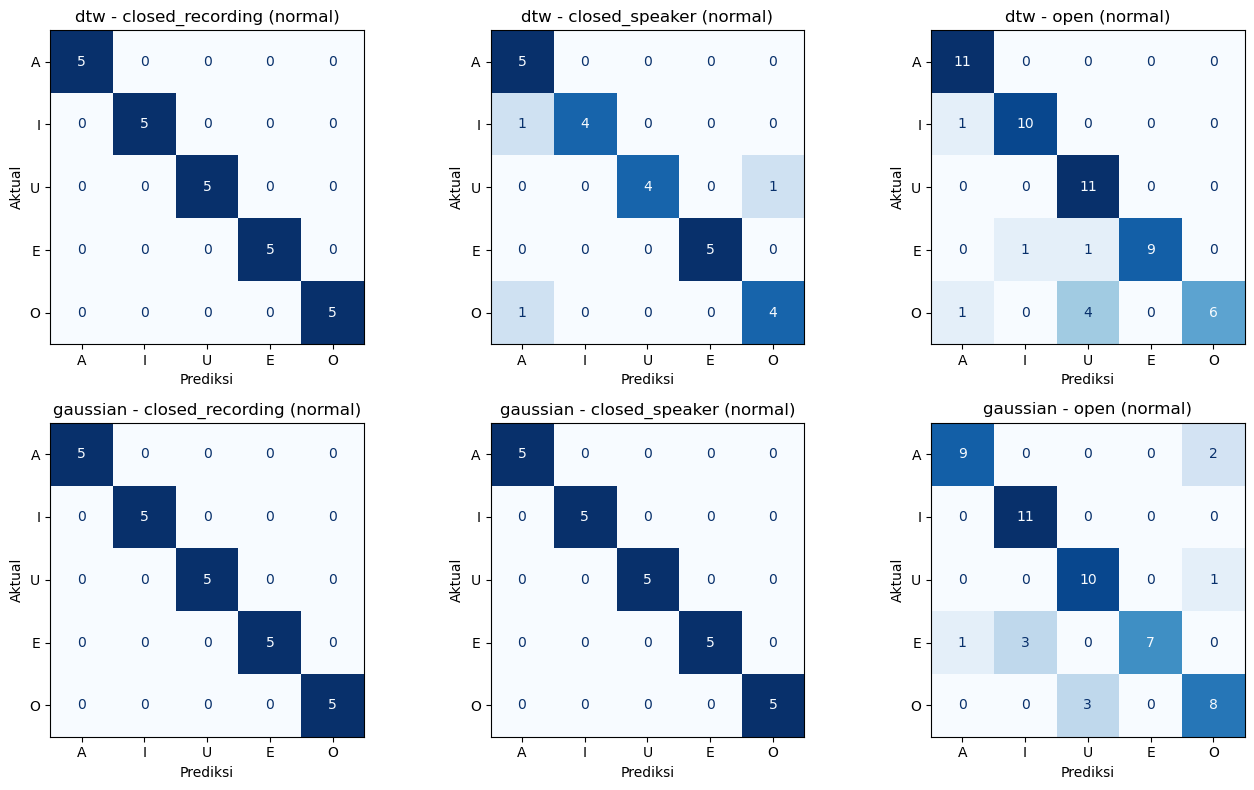

In [42]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm_dict = all_confusion_matrices(results_normal)

# Satu baris per sistem, satu kolom per skenario
systems_cm = list(dict.fromkeys(system for system, _ in cm_dict))
scenarios_cm = list(dict.fromkeys(scenario for _, scenario in cm_dict))
fig, axes = plt.subplots(
    len(systems_cm), len(scenarios_cm),
    figsize=(4.5 * len(scenarios_cm), 4 * len(systems_cm)), squeeze=False,
)
for ax in axes.ravel():
    ax.axis("off")
for (system, scenario), cm in cm_dict.items():
    ax = axes[systems_cm.index(system), scenarios_cm.index(scenario)]
    ax.axis("on")
    disp = ConfusionMatrixDisplay(confusion_matrix=cm.values, display_labels=cm.columns)
    disp.plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(f"{system} - {scenario} (normal)")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()

## 14. Pengaruh Variasi Pitch dan Durasi

Tambahan di luar spesifikasi: selain kondisi normal, closed speakers juga direkam dengan variasi pitch (HP = high pitch, LP = low pitch) dan durasi (SD = short duration, LD = long duration). Tabel berikut membandingkan akurasi kondisi normal, setiap variasi, kelompok variasi pitch (HP + LP), kelompok variasi durasi (SD + LD), dan **Overall** (semua kondisi digabung). Hanya skenario yang memiliki rekaman variasi yang ditampilkan.

In [43]:
skenario_variasi = results.loc[results["condition"] != "N", "scenario"].unique()
tabel_variasi = accuracy_per_condition(results[results["scenario"].isin(skenario_variasi)])

print("Tabel Variasi. Akurasi Normal vs Variasi Pitch dan Durasi (%)")
display(tabel_variasi.round(2))

Tabel Variasi. Akurasi Normal vs Variasi Pitch dan Durasi (%)


,,Normal,High Pitch,Low Pitch,Short Duration,Long Duration,Variasi Pitch,Variasi Durasi,Overall
Sistem,Skenario,,,,,,,,
DTW Template,Closed Speakers,88.0,80.0,64.0,96.0,92.0,72.0,94.0,84.0
Model Gaussian,Closed Speakers,100.0,76.0,72.0,96.0,96.0,74.0,96.0,88.0


### Rincian per Vowel dan per Speaker

Rincian akurasi closed speakers untuk setiap variasi kondisi rekaman (N, HP, LP, SD, LD) dan gabungan seluruh kondisi, per vowel dan per speaker. Tabel ini menjadi sumber Tabel 2.4, 2.5, 2.8, dan 2.9 pada laporan. Setiap sel kondisi berisi 5 rekaman.

In [44]:
KONDISI = ["N", "HP", "LP", "SD", "LD"]
NAMA_SISTEM = {"dtw": "DTW Template", "gaussian": "Model Gaussian"}


def akurasi_per_kondisi(results, system, by):
    """Akurasi closed speakers (%) per `by` (vowel_true atau speaker) untuk setiap kondisi rekaman."""
    cs = results[(results["scenario"] == "closed_speaker") & (results["system"] == system)]
    tabel = cs.pivot_table(index=by, columns="condition", values="correct", aggfunc="mean").reindex(columns=KONDISI) * 100
    tabel["Semua kondisi"] = cs.groupby(by)["correct"].mean() * 100
    tabel.loc["Rata-rata"] = list(cs.groupby("condition")["correct"].mean().reindex(KONDISI) * 100) + [cs["correct"].mean() * 100]
    tabel.columns.name = None
    return tabel.round(2)


for nomor, sistem in [("2.4", "dtw"), ("2.5", "gaussian")]:
    tabel = akurasi_per_kondisi(results, sistem, "vowel_true").reindex(VOWELS + ["Rata-rata"])
    tabel.index.name = "Vowel"
    print(f"Tabel {nomor}. Akurasi per vowel {NAMA_SISTEM[sistem]} pada closed speakers per variasi kondisi rekaman (%)")
    display(tabel)

for nomor, sistem in [("2.8", "dtw"), ("2.9", "gaussian")]:
    tabel = akurasi_per_kondisi(results, sistem, "speaker")
    tabel.index.name = "Speaker"
    print(f"Tabel {nomor}. Akurasi per speaker {NAMA_SISTEM[sistem]} pada closed speakers per variasi kondisi rekaman (%)")
    display(tabel)

Tabel 2.4. Akurasi per vowel DTW Template pada closed speakers per variasi kondisi rekaman (%)


,N,HP,LP,SD,LD,Semua kondisi
Vowel,,,,,,
A,100.0,100.0,60.0,100.0,100.0,92.0
I,80.0,80.0,20.0,100.0,100.0,76.0
U,80.0,60.0,100.0,100.0,100.0,88.0
E,100.0,80.0,80.0,100.0,100.0,92.0
O,80.0,80.0,60.0,80.0,60.0,72.0
Rata-rata,88.0,80.0,64.0,96.0,92.0,84.0


Tabel 2.5. Akurasi per vowel Model Gaussian pada closed speakers per variasi kondisi rekaman (%)


,N,HP,LP,SD,LD,Semua kondisi
Vowel,,,,,,
A,100.0,100.0,60.0,100.0,100.0,92.0
I,100.0,100.0,60.0,100.0,100.0,92.0
U,100.0,40.0,80.0,100.0,100.0,84.0
E,100.0,80.0,100.0,100.0,100.0,96.0
O,100.0,60.0,60.0,80.0,80.0,76.0
Rata-rata,100.0,76.0,72.0,96.0,96.0,88.0


Tabel 2.8. Akurasi per speaker DTW Template pada closed speakers per variasi kondisi rekaman (%)


,N,HP,LP,SD,LD,Semua kondisi
Speaker,,,,,,
S01,60.0,60.0,80.0,100.0,100.0,80.0
S02,80.0,80.0,100.0,100.0,80.0,88.0
S03,100.0,100.0,40.0,100.0,100.0,88.0
S04,100.0,100.0,60.0,80.0,80.0,84.0
S05,100.0,60.0,40.0,100.0,100.0,80.0
Rata-rata,88.0,80.0,64.0,96.0,92.0,84.0


Tabel 2.9. Akurasi per speaker Model Gaussian pada closed speakers per variasi kondisi rekaman (%)


,N,HP,LP,SD,LD,Semua kondisi
Speaker,,,,,,
S01,100.0,60.0,100.0,100.0,100.0,92.0
S02,100.0,80.0,80.0,100.0,100.0,92.0
S03,100.0,80.0,60.0,100.0,100.0,88.0
S04,100.0,100.0,60.0,80.0,80.0,84.0
S05,100.0,60.0,60.0,100.0,100.0,84.0
Rata-rata,100.0,76.0,72.0,96.0,96.0,88.0


## 15. Ringkasan Hasil Pengujian

Sel berikut menampilkan sistem dengan rata-rata akurasi tertinggi pada kondisi normal dan menyimpan seluruh tabel serta confusion matrix ke `results/evaluation/`, terpisah per kelompok kondisi (`normal/`, `pitch/`, `duration/`, `all/`), ditambah `table_per_condition.csv`. Analisis kualitatif mengenai perbedaan DTW dan Gaussian, pengaruh speaker, pengaruh variasi pitch dan durasi, serta kesalahan vowel dibahas pada laporan.

In [45]:
print("Akurasi rata-rata per sistem:")
display(ringkasan[["Rata-rata"]].round(2).sort_values("Rata-rata", ascending=False))

sistem_terbaik = ringkasan["Rata-rata"].idxmax()
print(
    f"Sistem dengan rata-rata tertinggi: {sistem_terbaik} "
    f"({ringkasan.loc[sistem_terbaik, 'Rata-rata']:.2f}%)"
)

evaluate_all(df=results, out_dir="results/evaluation")
print("Tabel CSV evaluasi dan confusion matrix disimpan di results/evaluation/.")

Akurasi rata-rata per sistem:


,Rata-rata
Sistem,
Model Gaussian,93.94
DTW Template,91.15


Sistem dengan rata-rata tertinggi: Model Gaussian (93.94%)
Tabel CSV evaluasi dan confusion matrix disimpan di results/evaluation/.


## 16. Export Hasil Pengujian

Hasil prediksi dan seluruh turunan tabel disimpan sebagai CSV agar bisa dipakai bersama untuk laporan dan pemeriksaan hasil.

In [46]:
from pathlib import Path

results.to_csv("results/predictions.csv", index=False)
folder = Path("results/evaluation")
file_evaluasi = sorted(p.relative_to(folder) for p in folder.rglob("*.csv"))
display(pd.DataFrame({"file": [str(p) for p in file_evaluasi]}))
print(f"Total file evaluasi: {len(file_evaluasi)}")

,file
0,all\confusion_matrices\dtw_closed_recording.csv
1,all\confusion_matrices\dtw_closed_recording_no...
2,all\confusion_matrices\dtw_closed_speaker.csv
3,all\confusion_matrices\dtw_closed_speaker_norm...
4,all\confusion_matrices\dtw_open.csv
5,all\confusion_matrices\dtw_open_normalized.csv
6,all\confusion_matrices\gaussian_closed_recordi...
7,all\confusion_matrices\gaussian_closed_recordi...
8,all\confusion_matrices\gaussian_closed_speaker...
9,all\confusion_matrices\gaussian_closed_speaker...


Total file evaluasi: 59
